# Robot de limpieza

Héctor Miguel Mejía Díaz  
TC2008B · Sesión 2 · Ejercicio para completar

Nombre del estudiante:  
Matrícula:

Usaremos la estructura de la demostración para comenzar M1. El movimiento y la visualización están preparados. Completa cuatro funciones para representar la suciedad, la acción del robot y las métricas.

No necesitas modificar el código de dibujo. Cada ejercicio tiene una comprobación breve. Los mensajes “Pendiente” indican funciones que todavía no has implementado. Las comprobaciones ayudan a revisar casos concretos; no sustituyen el análisis ni garantizan por sí solas que la actividad esté completa.

## 1. Preparación

Ejecuta las celdas en orden. Después de editar una función, ejecuta su celda y vuelve a correr su comprobación. Para una ejecución limpia puedes reiniciar la sesión y ejecutar todo.

Usamos la misma versión de Mesa que en la demostración. Si tenías otra versión importada, reinicia la sesión después de instalar.

In [3]:
%pip -q install "mesa==3.5.1" networkx

In [4]:
# Simulación de robots de limpieza reactivos con Mesa (actividad M1).
# Autor: Denzel López Cabrera. Matrícula: A01669190
# Base proporcionada por Héctor Miguel Mejía Díaz.
# Fecha de creación: 2026-11-04.
import mesa
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from types import SimpleNamespace
import random

print("Versión de Mesa:", mesa.__version__)

Versión de Mesa: 3.5.1


## 2. Reglas de M1

La habitación tiene M × N celdas. Todos los robots comienzan en `(0, 0)`, equivalente a `[1, 1]` en la consigna. Permitimos que compartan una celda.

En cada turno, si la celda está sucia, el robot aspira y permanece. Si está limpia, elige una de ocho direcciones y trata de moverse. Si el destino queda fuera, permanece. No limpia y se mueve en el mismo turno.

Los turnos se ejecutan secuencialmente en orden aleatorio. Contaremos movimientos efectivos. Ejecutaremos todo el horizonte y registraremos el primer paso con limpieza total; si no ocurre, el tiempo quedará en `None`.

Conserva estas convenciones al explicar tus resultados. La consigna oficial de Canvas determina los requisitos y la fecha de entrega.

In [5]:
DIRECCIONES = (
	(-1, -1), (0, -1), (1, -1),
	(-1, 0),           (1, 0),
	(-1, 1),  (0, 1),  (1, 1)
)


# Intenta mover un agente en una de ocho direcciones.
# Parámetro: agente, objeto con posicion, movimientos y model.
# Retorno: ninguno. Sólo cuenta cambios efectivos de posición.
def intentarMovimiento(agente):
	desplazamientoX, desplazamientoY = agente.model.random.choice(DIRECCIONES)
	posicionX, posicionY = agente.posicion
	nuevaX = posicionX + desplazamientoX
	nuevaY = posicionY + desplazamientoY
	dentroEspacio = (
		0 <= nuevaX < agente.model.ancho
		and 0 <= nuevaY < agente.model.alto
	)
	if dentroEspacio:
		agente.posicion = (nuevaX, nuevaY)
		agente.movimientos += 1

## 3. Cómo comprobar cada ejercicio

La siguiente función muestra si una comprobación pasó, falló o sigue pendiente. Cuando corrijas una función, vuelve a ejecutar la celda de su comprobación.

Los errores de sintaxis deben corregirse antes de poder ejecutar la celda. Otros errores mostrarán su tipo y mensaje.

In [6]:
pruebasSuperadas = {}


# Ejecuta una comprobación sin detener el resto del notebook.
# Parámetros: nombre, identificador; prueba, función de comprobación.
# Retorno: ninguno. Guarda el resultado en pruebasSuperadas.
def comprobarEjercicio(nombre, prueba):
	pruebasSuperadas[nombre] = False
	try:
		prueba()
	except NotImplementedError:
		print(nombre + ": pendiente de completar.")
	except Exception as error:
		print(nombre + ": revisar. " + type(error).__name__ + ": " + str(error))
	else:
		pruebasSuperadas[nombre] = True
		print(nombre + ": comprobaciones correctas.")

## 4. Ejercicio 1. Suciedad inicial

Completa `crearSuciedad`. Debe devolver un conjunto de posiciones distintas dentro de la habitación.

Calcula cuántas celdas estarán sucias a partir del porcentaje y redondea con `round`. Usa el generador recibido para seleccionar posiciones sin repetir. La selección debe depender de la semilla y no debe concentrarse siempre en las primeras celdas.

Pista: revisa `sample` de un generador `random.Random`. Para una habitación de 3 × 3 y 40 %, deben seleccionarse cuatro celdas. Con 0 %, el conjunto queda vacío.

Reemplaza la instrucción `raise` por tu implementación.

In [11]:
# Selecciona las posiciones inicialmente sucias.
# Parámetros: ancho y alto, enteros positivos; porcentajeSuciedad,
# porcentaje entre 0 y 100; generador, objeto random.Random.
# Retorno: conjunto de tuplas (x, y), sin posiciones repetidas.
def crearSuciedad(ancho, alto, porcentajeSuciedad, generador):
	totalCeldas = ancho * alto
	cantidadSucias = round(totalCeldas * porcentajeSuciedad / 100)
	todasLasCeldas = [(x, y) for x in range(ancho) for y in range(alto)]
	celdasElegidas = generador.sample(todasLasCeldas, cantidadSucias)
	return set(celdasElegidas)

In [12]:
# Comprueba cantidad, límites, extremos y repetibilidad de la selección.
# Parámetros: ninguno.
# Retorno: ninguno. Produce AssertionError si una condición falla.
def probarSuciedad():
	suciedad = crearSuciedad(3, 3, 40.0, random.Random(42))
	assert isinstance(suciedad, set), "Devuelve un conjunto."
	assert len(suciedad) == 4, "Revisa el cálculo y redondeo de la cantidad."
	assert all(0 <= x < 3 and 0 <= y < 3 for x, y in suciedad), "Hay posiciones fuera."
	assert suciedad == crearSuciedad(3, 3, 40.0, random.Random(42)), "Usa el generador recibido."
	assert crearSuciedad(3, 3, 0.0, random.Random(42)) == set(), "Revisa el caso 0 %."
	assert len(crearSuciedad(3, 3, 100.0, random.Random(42))) == 9, "Revisa el caso 100 %."


comprobarEjercicio("Ejercicio 1", probarSuciedad)

Ejercicio 1: comprobaciones correctas.


## 5. Ejercicio 2. Acción del robot

Completa `actuarRobot`. Consulta si `robot.posicion` pertenece a `robot.model.celdasSucias`.

Si está sucia, elimina esa posición del conjunto. Si está limpia, llama a `intentarMovimiento(robot)`. El contador no debe aumentar al limpiar. No cambies la posición cuando la acción sea limpiar.

Primero escribe la regla en palabras. Después tradúcela a Python.

In [9]:
# Ejecuta una acción de limpieza o un intento de movimiento.
# Parámetro: robot, agente con posicion, movimientos y model.
# Retorno: ninguno. Modifica el agente o la suciedad de su modelo.
def actuarRobot(robot):
	if robot.posicion in robot.model.celdasSucias:
		robot.model.celdasSucias.remove(robot.posicion)
	else:
		intentarMovimiento(robot)

In [10]:
# Comprueba limpieza y movimiento sin crear todavía una habitación completa.
# Parámetros: ninguno.
# Retorno: ninguno. Produce AssertionError si una condición falla.
def probarAccion():
	entorno = SimpleNamespace(ancho=3, alto=3, random=random.Random(1),
							  celdasSucias={(1, 1)})
	robot = SimpleNamespace(posicion=(1, 1), movimientos=0, model=entorno)
	actuarRobot(robot)
	assert entorno.celdasSucias == set(), "La celda debe quedar limpia."
	assert robot.posicion == (1, 1), "Al limpiar debe permanecer."
	assert robot.movimientos == 0, "Limpiar no cuenta como movimiento."
	actuarRobot(robot)
	assert robot.posicion != (1, 1), "Desde el centro, todas las direcciones son válidas."
	assert robot.movimientos == 1, "Registra un movimiento efectivo."
	borde = SimpleNamespace(ancho=1, alto=1, random=random.Random(2), celdasSucias=set())
	robotBorde = SimpleNamespace(posicion=(0, 0), movimientos=0, model=borde)
	actuarRobot(robotBorde)
	assert robotBorde.posicion == (0, 0), "El robot debe permanecer en la habitación."
	assert robotBorde.movimientos == 0, "Un intento fallido no incrementa movimientos."


comprobarEjercicio("Ejercicio 2", probarAccion)

Ejercicio 2: comprobaciones correctas.


## 6. Ejercicio 3. Porcentaje de limpieza

Completa `calcularPorcentajeLimpio`. Cuenta las celdas totales y las que siguen sucias. Devuelve un porcentaje entre 0 y 100.

El resultado incluye las celdas que ya estaban limpias al inicio. Por ejemplo, una habitación de 2 × 2 con una celda sucia tiene 75 % de celdas limpias.

In [16]:
# Calcula el porcentaje actual de celdas limpias.
# Parámetros: ancho y alto, dimensiones; celdasSucias, conjunto de posiciones.
# Retorno: porcentaje de limpieza como número entre 0 y 100.
def calcularPorcentajeLimpio(ancho, alto, celdasSucias):
	totalCeldas = ancho * alto
	celdasLimpias = totalCeldas - len(celdasSucias)
	return celdasLimpias / totalCeldas * 100

In [19]:
# Comprueba porcentajes para una habitación vacía, parcial y totalmente sucia.
# Parámetros: ninguno.
# Retorno: ninguno. Produce AssertionError si una condición falla.
def probarPorcentaje():
	assert calcularPorcentajeLimpio(2, 2, set()) == 100.0, "Sin suciedad: 100 %."
	assert calcularPorcentajeLimpio(2, 2, {(0, 0)}) == 75.0, "Una sucia de cuatro: 75 %."
	todas = {(0, 0), (0, 1), (1, 0), (1, 1)}
	assert calcularPorcentajeLimpio(2, 2, todas) == 0.0, "Todas sucias: 0 %."


comprobarEjercicio("Ejercicio 3", probarPorcentaje)

Ejercicio 3: comprobaciones correctas.


## 7. Ejercicio 4. Primer paso con limpieza total

Completa `actualizarTiempoLimpieza`. Recibe la suciedad actual, el paso actual y el tiempo registrado anteriormente.

Si no queda suciedad y no había tiempo registrado, devuelve el paso actual. En cualquier otro caso conserva el valor anterior. Si todavía no se ha observado limpieza total, el valor será `None`.

No reemplaces un tiempo registrado por un paso posterior. Si la habitación comienza limpia, el primer tiempo es cero.

In [18]:
# Actualiza el primer paso en que se alcanza la limpieza total.
# Parámetros: celdasSucias, posiciones pendientes; pasoActual, entero;
# tiempoAnterior, primer paso registrado o None.
# Retorno: primer tiempo observado o None si no se ha alcanzado la limpieza.
def actualizarTiempoLimpieza(celdasSucias, pasoActual, tiempoAnterior):
	tiempoResultado = tiempoAnterior
	if len(celdasSucias) == 0 and tiempoAnterior is None:
		tiempoResultado = pasoActual
	return tiempoResultado

In [20]:
# Comprueba éxito inicial, éxito posterior y conservación del primer tiempo.
# Parámetros: ninguno.
# Retorno: ninguno. Produce AssertionError si una condición falla.
def probarTiempo():
	assert actualizarTiempoLimpieza({(0, 0)}, 4, None) is None, "Todavía queda suciedad."
	assert actualizarTiempoLimpieza(set(), 0, None) == 0, "Ya estaba limpia al inicio."
	assert actualizarTiempoLimpieza(set(), 7, None) == 7, "Registra el primer éxito."
	assert actualizarTiempoLimpieza(set(), 8, 7) == 7, "Conserva el primer tiempo."


comprobarEjercicio("Ejercicio 4", probarTiempo)

Ejercicio 4: comprobaciones correctas.


## 8. Integración con Mesa

Las siguientes clases están preparadas. Localiza dónde llaman a cada función que completaste.

`RobotLimpieza.step` delega la decisión a tu función. `Habitacion.step` organiza los turnos, actualiza el tiempo de limpieza y registra datos. El registro suma los movimientos efectivos de todos los agentes.

Lee estas clases antes de ejecutar; no necesitas modificarlas para resolver los cuatro ejercicios.

In [21]:
class RobotLimpieza(mesa.Agent):

	# Inicializa al robot en la celda de origen y lo registra en Mesa.
	# Parámetro: model, habitación a la que pertenece.
	# Retorno: ninguno.
	def __init__(self, model):
		super().__init__(model)
		self.posicion = (0, 0)
		self.movimientos = 0

	# Ejecuta la función de comportamiento completada por el estudiante.
	# Parámetros: ninguno.
	# Retorno: ninguno.
	def step(self):
		actuarRobot(self)


class Habitacion(mesa.Model):

	# Crea la habitación, la suciedad y los robots.
	# Parámetros: ancho, alto y numeroAgentes, enteros positivos;
	# porcentajeSuciedad, valor entre 0 y 100; semilla, semilla aleatoria.
	# Retorno: ninguno.
	def __init__(self, ancho=6, alto=6, numeroAgentes=1,
				 porcentajeSuciedad=40.0, semilla=42):
		super().__init__(rng=semilla)
		if any(type(valor) is not int or valor < 1
			   for valor in (ancho, alto, numeroAgentes)):
			raise ValueError("Dimensiones y agentes deben ser enteros positivos.")
		if not 0.0 <= porcentajeSuciedad <= 100.0:
			raise ValueError("El porcentaje debe estar entre 0 y 100.")
		self.ancho = ancho
		self.alto = alto
		self.pasos = 0
		self.historial = []
		self.celdasSucias = crearSuciedad(ancho, alto, porcentajeSuciedad, self.random)
		self.tiempoLimpieza = actualizarTiempoLimpieza(self.celdasSucias, 0, None)
		for _ in range(numeroAgentes):
			RobotLimpieza(self)
		self.registrarDatos()

	# Activa todos los robots y registra el estado al terminar el paso.
	# Parámetros: ninguno.
	# Retorno: ninguno.
	def step(self):
		self.agents.shuffle_do("step")
		self.pasos += 1
		self.tiempoLimpieza = actualizarTiempoLimpieza(
			self.celdasSucias, self.pasos, self.tiempoLimpieza
		)
		self.registrarDatos()

	# Guarda métricas del estado actual.
	# Parámetros: ninguno.
	# Retorno: ninguno. Agrega una fila al historial.
	def registrarDatos(self):
		self.historial.append({
			"paso": self.pasos,
			"porcentajeLimpio": calcularPorcentajeLimpio(
				self.ancho, self.alto, self.celdasSucias
			),
			"movimientos": sum(robot.movimientos for robot in self.agents)
		})

## 9. Visualización preparada

La suciedad aparece en café. Cada círculo representa una posición ocupada y su número indica cuántos robots contiene. La animación es opcional.

Esta celda utiliza las mismas funciones de apoyo de la demostración.

In [22]:
# Guarda una copia del estado para dibujarlo después.
# Parámetros: modelo, modelo con agentes; suciedad, posiciones sucias o None.
# Retorno: diccionario independiente con paso, posiciones y suciedad.
def capturarEstado(modelo, suciedad=None):
	return {
		"paso": modelo.pasos,
		"posiciones": [agente.posicion for agente in modelo.agents],
		"suciedad": set() if suciedad is None else set(suciedad)
	}


# Representa agentes y, si existe, suciedad en una cuadrícula.
# Parámetros: modelo, dimensiones; estado, captura; eje, eje de Matplotlib.
# Retorno: ninguno.
def dibujarEstado(modelo, estado, eje):
	eje.clear()
	for posicionX, posicionY in estado["suciedad"]:
		eje.add_patch(plt.Rectangle(
			(posicionX, posicionY), 1, 1, facecolor="sandybrown"
		))
	ocupacion = {}
	for posicion in estado["posiciones"]:
		ocupacion[posicion] = ocupacion.get(posicion, 0) + 1
	for (posicionX, posicionY), cantidad in ocupacion.items():
		eje.scatter(posicionX + 0.5, posicionY + 0.5, s=270, color="#003366")
		eje.text(posicionX + 0.5, posicionY + 0.5, str(cantidad),
				 ha="center", va="center", color="white")
	eje.set_xlim(0, modelo.ancho)
	eje.set_ylim(0, modelo.alto)
	eje.set_xticks(range(modelo.ancho + 1))
	eje.set_yticks(range(modelo.alto + 1))
	eje.set_aspect("equal")
	eje.grid(alpha=0.25)
	eje.set_title(f"Paso {estado['paso']}")
	eje.set_xlabel("x")
	eje.set_ylabel("y")


# Muestra los estados inicial y final de una ejecución.
# Parámetros: modelo, dimensiones; estados, lista no vacía de capturas.
# Retorno: ninguno.
def mostrarExtremos(modelo, estados):
	figura, ejes = plt.subplots(1, 2, figsize=(10, 4))
	dibujarEstado(modelo, estados[0], ejes[0])
	dibujarEstado(modelo, estados[-1], ejes[1])
	plt.tight_layout()
	plt.show()


# Reproduce capturas sin ejecutar nuevos pasos de simulación.
# Parámetros: modelo, dimensiones; estados, lista de capturas.
# Retorno: objeto HTML con controles de reproducción.
def crearAnimacion(modelo, estados):
	figura, eje = plt.subplots(figsize=(5, 5))

	# Dibuja la captura solicitada por FuncAnimation.
	# Parámetro: indiceEstado, índice de captura.
	# Retorno: ninguno.
	def actualizarImagen(indiceEstado):
		dibujarEstado(modelo, estados[indiceEstado], eje)

	animacion = FuncAnimation(figura, actualizarImagen,
							  frames=len(estados), interval=180, repeat=False)
	plt.close(figura)
	return HTML(animacion.to_jshtml())

## 10. Primera ejecución del robot

Vuelve a correr las cuatro comprobaciones después de modificar tus funciones. Esta celda crea un modelo nuevo sólo cuando las comprobaciones han pasado.

Comienza con un robot. Comprueba que la limpieza aumenta y que permanece dentro de la habitación. Después modifica la cantidad de agentes.

Si todavía falta un ejercicio, puedes probar el anterior por separado sin ejecutar una simulación completa.

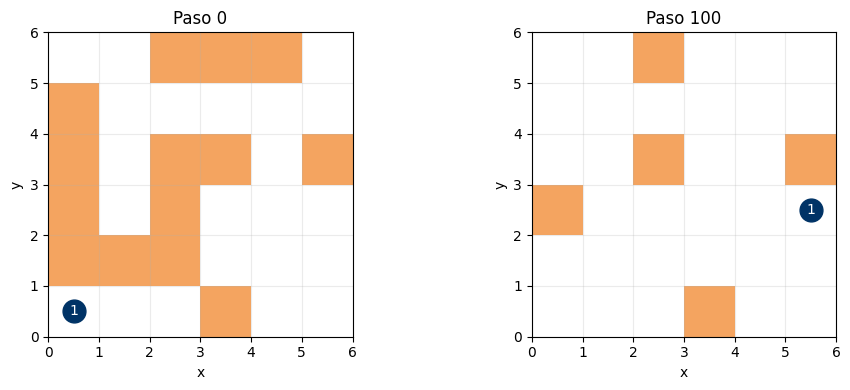

,paso,porcentajeLimpio,movimientos
96,96,86.111111,67
97,97,86.111111,67
98,98,86.111111,68
99,99,86.111111,69
100,100,86.111111,70


Movimientos efectivos: 70.0
No se alcanzó la limpieza total dentro del límite.


In [23]:
modelo = None
estados = []
PASOS_MAXIMOS = 100
listoParaEjecutar = len(pruebasSuperadas) == 4 and all(pruebasSuperadas.values())

if listoParaEjecutar:
	modelo = Habitacion(ancho=6, alto=6, numeroAgentes=1,
						porcentajeSuciedad=40.0, semilla=42)
	estados.append(capturarEstado(modelo, modelo.celdasSucias))
	for _ in range(PASOS_MAXIMOS):
		modelo.step()
		estados.append(capturarEstado(modelo, modelo.celdasSucias))
	mostrarExtremos(modelo, estados)
	datos = pd.DataFrame(modelo.historial)
	display(datos.tail())
	print("Movimientos efectivos:", datos.iloc[-1]["movimientos"])
	if modelo.tiempoLimpieza is None:
		print("No se alcanzó la limpieza total dentro del límite.")
	else:
		print("Primer paso con limpieza total:", modelo.tiempoLimpieza)
else:
	print("Completa los ejercicios y vuelve a ejecutar sus comprobaciones.")

In [24]:
if modelo is not None:
	display(crearAnimacion(modelo, estados))
else:
	print("La animación estará disponible después de completar los ejercicios.")

## 11. Experimentos y análisis individual

Construye una comparación que permita estudiar el efecto de la cantidad de agentes. Una primera opción es usar 1, 3 y 5 robots con varias semillas por configuración, conservando dimensiones, suciedad solicitada y límite de pasos. La cantidad de repeticiones se acuerda en clase.

Prepara una tabla con agentes, semilla, porcentaje inicial efectivo, pasos ejecutados, limpieza total alcanzada, primer tiempo de limpieza, porcentaje limpio final y movimientos. Puedes usar la comparación de la plaza como referencia, adaptando las métricas. No interpretes el límite como un tiempo exitoso. Si calculas el promedio de tiempos sólo entre éxitos, indica cuántas ejecuciones alcanzaron esa condición.

Escribe tus conclusiones relacionando los datos con las reglas. Explica por qué los robots pueden repetir recorridos y cómo influye que todos comiencen juntos.

## Entrega

Consulta la consigna oficial de M1. El reporte es individual e incluye el enlace al repositorio de GitHub. Revisa encabezado, autor, matrícula, fecha y comentarios de las funciones. No utilices `break` ni `continue`. Conserva los nombres que exige Mesa.

La meta mínima de la sesión es un robot que limpie, se mueva y respete los límites. Las repeticiones y el análisis pueden continuar en casa para revisarlos el jueves.

## Referencias

Mesa 3.5.1: https://mesa.readthedocs.io/en/v3.5.1/  
M1. Actividad y Estándar de Codificación del curso TC2008B.  
Wooldridge, M. (2002). *An introduction to multiagent systems*. John Wiley & Sons.

In [25]:
# Ejecuta una simulación completa sin generar imágenes.
# Parámetros: numeroAgentes, cantidad de robots; semilla, semilla aleatoria;
# pasosMaximos, límite de pasos; ancho y alto, dimensiones;
# porcentajeSuciedad, porcentaje solicitado de celdas sucias.
# Retorno: diccionario con los indicadores de la ejecución.
def ejecutarExperimento(numeroAgentes, semilla, pasosMaximos=100,
						ancho=6, alto=6, porcentajeSuciedad=40.0):
	modeloPrueba = Habitacion(ancho=ancho, alto=alto,
							  numeroAgentes=numeroAgentes,
							  porcentajeSuciedad=porcentajeSuciedad,
							  semilla=semilla)
	porcentajeInicialSucio = 100.0 - modeloPrueba.historial[0]["porcentajeLimpio"]
	for _ in range(pasosMaximos):
		modeloPrueba.step()
	ultimoRegistro = modeloPrueba.historial[-1]
	return {
		"agentes": numeroAgentes,
		"semilla": semilla,
		"porcentajeInicialSucio": porcentajeInicialSucio,
		"pasosEjecutados": modeloPrueba.pasos,
		"limpiezaTotal": modeloPrueba.tiempoLimpieza is not None,
		"tiempoLimpieza": modeloPrueba.tiempoLimpieza,
		"porcentajeLimpioFinal": ultimoRegistro["porcentajeLimpio"],
		"movimientos": ultimoRegistro["movimientos"]
	}


PASOS_EXPERIMENTO = 200
resultados = []
for numeroAgentes in [1, 3, 5]:
	for semillaPrueba in [10, 20, 30, 40, 50]:
		resultados.append(ejecutarExperimento(numeroAgentes, semillaPrueba,
											  PASOS_EXPERIMENTO))
tablaResultados = pd.DataFrame(resultados)
display(tablaResultados.round(2))

resumen = tablaResultados.groupby("agentes").agg(
	repeticiones=("semilla", "count"),
	exitos=("limpiezaTotal", "sum"),
	tiempoMedioExitos=("tiempoLimpieza", "mean"),
	tiempoDesviacion=("tiempoLimpieza", "std"),
	limpioFinalMedio=("porcentajeLimpioFinal", "mean"),
	movimientosMedios=("movimientos", "mean"),
	movimientosDesviacion=("movimientos", "std")
)
display(resumen.round(2))

,agentes,semilla,porcentajeInicialSucio,pasosEjecutados,limpiezaTotal,tiempoLimpieza,porcentajeLimpioFinal,movimientos
0,1,10,38.89,200,False,NaN,97.22,138
1,1,20,38.89,200,False,NaN,97.22,140
2,1,30,38.89,200,True,176.0,100.00,137
3,1,40,38.89,200,False,NaN,94.44,141
4,1,50,38.89,200,False,NaN,94.44,143
5,3,10,38.89,200,True,120.0,100.00,463
6,3,20,38.89,200,True,84.0,100.00,412
7,3,30,38.89,200,True,101.0,100.00,432
8,3,40,38.89,200,True,103.0,100.00,441
9,3,50,38.89,200,True,64.0,100.00,423


,repeticiones,exitos,tiempoMedioExitos,tiempoDesviacion,limpioFinalMedio,movimientosMedios,movimientosDesviacion
agentes,,,,,,,
1,5,1,176.0,NaN,96.67,139.8,2.39
3,5,5,94.4,21.24,100.00,434.2,19.36
5,5,5,95.2,46.05,100.00,729.6,15.44


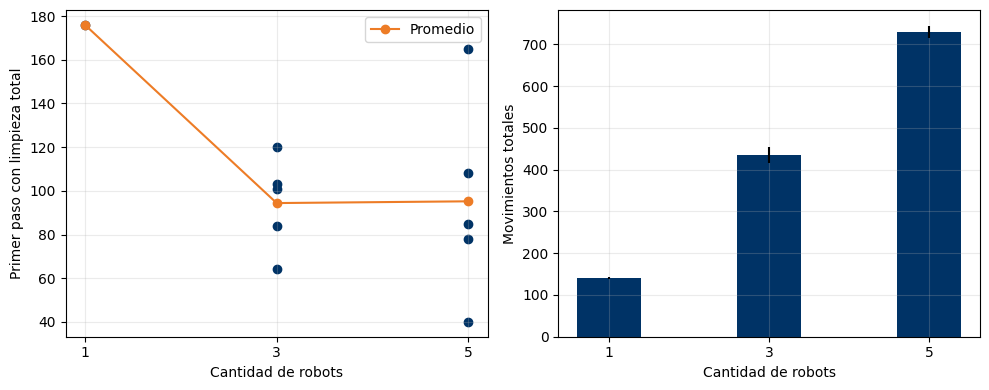

In [26]:
# Gráficas de tiempo de limpieza y movimientos según la cantidad de robots.
figuraResultados, ejesResultados = plt.subplots(1, 2, figsize=(10, 4))
for numeroAgentes, grupo in tablaResultados.groupby("agentes"):
	exitosos = grupo[grupo["limpiezaTotal"]]
	ejesResultados[0].scatter([numeroAgentes] * len(exitosos),
							  exitosos["tiempoLimpieza"], color="#003366")
ejesResultados[0].plot(resumen.index, resumen["tiempoMedioExitos"],
					   color="#ED7C26", marker="o", label="Promedio")
ejesResultados[0].set_ylabel("Primer paso con limpieza total")
ejesResultados[0].legend()
ejesResultados[1].bar(resumen.index, resumen["movimientosMedios"],
					  yerr=resumen["movimientosDesviacion"], color="#003366")
ejesResultados[1].set_ylabel("Movimientos totales")
for eje in ejesResultados:
	eje.set_xlabel("Cantidad de robots")
	eje.set_xticks([1, 3, 5])
	eje.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Informe M1: Robot de limpieza reactivo

**Denzel López Cabrera · A01669190**
TC2008B Modelación de sistemas multiagentes con gráficas computacionales
5 de noviembre de 2026

Repositorio: https://github.com/A01669190/TC2008B-M1-Robot-Limpieza

## 1. Introducción

En esta actividad simulé uno o varios robots de limpieza dentro de una habitación dividida en celdas. Los robots son reactivos: no tienen memoria, no planean una ruta y no se comunican entre ellos. Lo único que hacen es ver si la celda en la que están está sucia y actuar en consecuencia. La pregunta que quería responder es qué tanto ayuda poner más robots: si la habitación se limpia más rápido y cuánto movimiento extra cuesta.

La simulación la hice en Python con Mesa 3.5.1, partiendo del notebook que se trabajó en clase. Ahí completé las funciones de la suciedad inicial, la decisión del robot, el porcentaje de limpieza y el registro del tiempo, y después agregué los experimentos y las gráficas.

## 2. Descripción del modelo

**Entorno.** La habitación es una cuadrícula de M × N celdas. Al inicio se ensucia un porcentaje de celdas elegidas al azar y sin repetir. La cantidad se calcula como M × N × porcentaje / 100 y se redondea. Las posiciones dependen de la semilla, así que cada corrida se puede repetir.

**Agentes.** Todos los robots empiezan en la celda (0, 0), que corresponde a la [1, 1] de la consigna. Varios robots pueden estar en la misma celda. En cada turno un robot hace solo una de estas dos cosas:

- Si su celda está sucia, aspira y se queda en el mismo lugar.
- Si está limpia, elige al azar una de las 8 direcciones vecinas. Si el destino está fuera de la habitación, se queda donde está.

**Pasos.** En cada paso global todos los robots actúan una vez, en orden aleatorio (`shuffle_do` de Mesa). Como actúan uno tras otro, si dos robots llegan a la misma celda sucia, el primero la limpia y el segundo ya la encuentra limpia.

**Métricas.** Después de cada paso registro el porcentaje de celdas limpias y los movimientos acumulados de todos los robots. Solo cuento como movimiento cuando el robot de verdad cambia de celda; ni limpiar ni chocar con la pared suman. También guardo el primer paso en el que la habitación queda totalmente limpia. Si eso no pasa antes del límite, el tiempo queda como `None` y no lo uso como si hubiera sido un éxito.

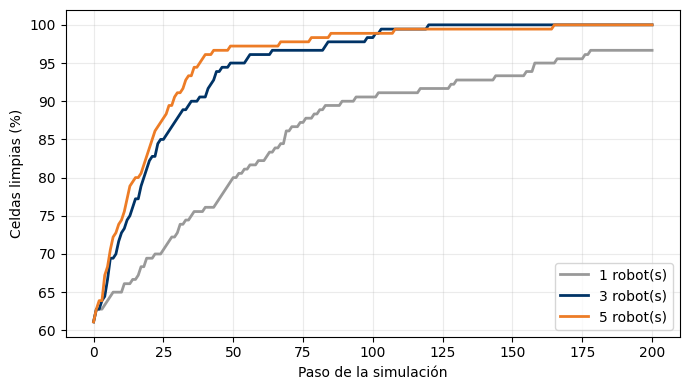

,movimientosHastaLimpiar
agentes,
1,116.0
3,201.4
5,337.0


In [27]:
# Calcula la evolución promedio del porcentaje limpio y los movimientos
# acumulados en el paso en que se alcanzó la limpieza total.
curvasPromedio = {}
movimientosHastaLimpiar = []
for numeroAgentes in [1, 3, 5]:
	curvasAgentes = []
	for semillaPrueba in [10, 20, 30, 40, 50]:
		modeloCurva = Habitacion(numeroAgentes=numeroAgentes, semilla=semillaPrueba)
		for _ in range(PASOS_EXPERIMENTO):
			modeloCurva.step()
		historialCurva = pd.DataFrame(modeloCurva.historial)
		curvasAgentes.append(historialCurva["porcentajeLimpio"])
		if modeloCurva.tiempoLimpieza is not None:
			movimientosHastaLimpiar.append({
				"agentes": numeroAgentes,
				"movimientosHastaLimpiar":
					historialCurva.loc[modeloCurva.tiempoLimpieza, "movimientos"]
			})
	curvasPromedio[numeroAgentes] = pd.concat(curvasAgentes, axis=1).mean(axis=1)

figuraCurvas, ejeCurvas = plt.subplots(figsize=(7, 4))
coloresCurvas = {1: "#999999", 3: "#003366", 5: "#ED7C26"}
for numeroAgentes, curva in curvasPromedio.items():
	ejeCurvas.plot(curva.index, curva, color=coloresCurvas[numeroAgentes],
				   linewidth=2, label=str(numeroAgentes) + " robot(s)")
ejeCurvas.set_xlabel("Paso de la simulación")
ejeCurvas.set_ylabel("Celdas limpias (%)")
ejeCurvas.grid(alpha=0.25)
ejeCurvas.legend(loc="lower right")
plt.tight_layout()
plt.show()

tablaMovimientos = pd.DataFrame(movimientosHastaLimpiar)
display(tablaMovimientos.groupby("agentes")["movimientosHastaLimpiar"].mean().round(1))

## 5. Análisis

**Tiempo de limpieza.** El cambio más grande está entre 1 y 3 robots. Con uno solo, la habitación quedó limpia en 1 de 5 ejecuciones y las demás terminaron entre 94 % y 97 %: el robot casi acaba, pero las últimas celdas sucias le cuestan mucho porque tiene que caer en ellas por casualidad. Con 3 robots se limpió todo en las 5 ejecuciones, en 94 pasos en promedio. En la gráfica de evolución se ve lo mismo: a los 50 pasos un robot lleva 80 % y tres robots ya van en 95 %.

Lo que no esperaba es que con 5 robots el tiempo promedio fuera prácticamente igual que con 3 (95.2 contra 94.4). La mejor ejecución de todas fue con 5 robots (40 pasos), pero también una de las peores (165 pasos), y la desviación estándar se duplicó. En la gráfica de evolución, los 5 robots sí avanzan un poco más rápido al principio, pero al final se emparejan con los 3. Con solo 5 semillas por configuración la diferencia de un paso no significa nada; lo que sí se puede decir es que, en una habitación de 36 celdas, pasar de 3 a 5 robots no mejoró de forma clara el tiempo.

**Por qué pasa esto.** Creo que se explica con las reglas del modelo:

- **Todos empiezan juntos en (0, 0).** Durante los primeros pasos los robots están en la misma esquina, recorriendo la misma zona. Varios llegan a las mismas celdas y solo el primero limpia; los demás gastan su turno en una celda que ya no tiene nada.
- **Movimiento aleatorio y sin memoria.** Un robot no sabe por dónde ya pasó ni por dónde pasaron los otros, así que repite recorridos todo el tiempo. Puede volver a una celda limpia varias veces mientras la última celda sucia sigue al otro lado.
- **La última celda decide todo.** El tiempo de limpieza total depende de que algún robot llegue a la última celda sucia, y eso es pura suerte. Por eso la variación es tan grande y por eso agregar robots ayuda cada vez menos.
- **Las paredes.** En las orillas y esquinas varias direcciones quedan fuera, así que el robot pierde turnos sin moverse. Esto afecta más al principio, cuando todos están en la esquina.

**Movimientos.** Los movimientos totales crecen casi en proporción a la cantidad de robots: unos 140 con uno, 434 con tres y 730 con cinco, o sea alrededor de 145 por robot. Tiene sentido, porque un robot en una celda limpia siempre intenta moverse, y una vez que la habitación queda limpia los robots siguen caminando hasta el paso 200 sin hacer nada útil. Si solo cuento los movimientos hasta que se limpió todo, 5 robots necesitaron 337 en promedio contra 201 de 3 robots, para casi el mismo tiempo. Es decir, con 5 robots se gastó bastante más movimiento para obtener el mismo resultado.

## 6. Conclusiones

- Aumentar la cantidad de robots sí reduce el tiempo de limpieza, pero el beneficio no es lineal. En este escenario el salto importante fue de 1 a 3 robots; de 3 a 5 casi no hubo diferencia en el tiempo promedio.
- Los movimientos crecen casi en proporción a los robots, así que cada robot extra cuesta lo mismo pero aporta cada vez menos. Si moverse tuviera un costo (batería, desgaste), 3 robots serían la mejor opción para una habitación de 6 × 6.
- Las limitaciones vienen de que el agente es puramente reactivo: no recuerda, no se coordina y todos parten del mismo punto. Si los robots empezaran en lugares distintos, recordaran las celdas visitadas o se repartieran la habitación, seguramente aprovecharían mejor a cada agente.
- Para sacar conclusiones más firmes haría falta correr más semillas, probar más cantidades de robots (2, 4, 8…) y otros tamaños de habitación y porcentajes de suciedad, y detener la simulación cuando todo esté limpio para no contar movimientos inútiles.

## Referencias

Mesa Project. (2025). *Mesa 3.5.1 documentation*. https://mesa.readthedocs.io/en/v3.5.1/

Mejía Díaz, H. M. (2026). *Sesión 2: Personas en una plaza y Robot de limpieza* [Notebooks de Jupyter]. TC2008B, Tecnológico de Monterrey.

Wooldridge, M. (2002). *An introduction to multiagent systems*. John Wiley & Sons.